In [4]:
import sys
print(sys.executable)

c:\Users\GA LAPTOP\AppData\Local\Programs\Python\Python310\python.exe


In [5]:
import sys
print(sys.executable)

c:\Users\GA LAPTOP\AppData\Local\Programs\Python\Python310\python.exe


In [6]:
import sys
print(sys.executable)

c:\Users\GA LAPTOP\AppData\Local\Programs\Python\Python310\python.exe


In [1]:
import sys
print(sys.executable)

e:\DEEPGUARD\deepguard_env\Scripts\python.exe


In [2]:
import sys
print(sys.executable)

e:\DEEPGUARD\deepguard_env\Scripts\python.exe


In [3]:
import sys
print(sys.executable)

e:\DEEPGUARD\deepguard_env\Scripts\python.exe


In [4]:
import pandas as pd
import numpy as np

print("DeepGuard pipeline started 🚀")

DeepGuard pipeline started 🚀


In [5]:
import os

In [6]:
df = pd.read_csv("../datasets/text/WELFAKE_Dataset.csv")
df.head()

,Unnamed: 0,title,text,label
0,0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1
1,1,NaN,Did they post their votes for Hillary already?,1
2,2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1
3,3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0
4,4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1


In [7]:
print(df.shape)
print(df.columns)
df.info()

(72134, 4)
Index(['Unnamed: 0', 'title', 'text', 'label'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72134 entries, 0 to 72133
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  72134 non-null  int64 
 1   title       71576 non-null  object
 2   text        72095 non-null  object
 3   label       72134 non-null  int64 
dtypes: int64(2), object(2)
memory usage: 2.2+ MB


In [8]:
df = df.drop(columns=["Unnamed: 0"])

In [9]:
df = df.dropna(subset=["text", "title"])

In [10]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 71537 entries, 0 to 72133
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   title   71537 non-null  object
 1   text    71537 non-null  object
 2   label   71537 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 2.2+ MB


title    0
text     0
label    0
dtype: int64

In [11]:
df["content"] = df["title"] + " " + df["text"]
df.head()

,title,text,label,content
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,No comment is expected from Barack Obama Membe...,1,LAW ENFORCEMENT ON HIGH ALERT Following Threat...
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,"Now, most of the demonstrators gathered last ...",1,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...
3,"Bobby Jindal, raised Hindu, uses story of Chri...",A dozen politically active pastors came here f...,0,"Bobby Jindal, raised Hindu, uses story of Chri..."
4,SATAN 2: Russia unvelis an image of its terrif...,"The RS-28 Sarmat missile, dubbed Satan 2, will...",1,SATAN 2: Russia unvelis an image of its terrif...
5,About Time! Christian Group Sues Amazon and SP...,All we can say on this one is it s about time ...,1,About Time! Christian Group Sues Amazon and SP...


In [12]:
df = df[["content", "label"]]
df.head()

,content,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",0
4,SATAN 2: Russia unvelis an image of its terrif...,1
5,About Time! Christian Group Sues Amazon and SP...,1


In [13]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)   # remove URLs
    text = re.sub(r"[^a-zA-Z\s]", "", text)      # remove numbers & punctuation
    text = re.sub(r"\s+", " ", text).strip()     # remove extra spaces
    return text

df["content"] = df["content"].apply(clean_text)
df.head()

,content,label
0,law enforcement on high alert following threat...,1
2,unbelievable obamas attorney general says most...,1
3,bobby jindal raised hindu uses story of christ...,0
4,satan russia unvelis an image of its terrifyin...,1
5,about time christian group sues amazon and spl...,1


In [14]:
from sklearn.model_selection import train_test_split

X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(max_features=5000)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

In [16]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_vec, y_train)

LogisticRegression(max_iter=1000)

In [17]:
y_pred = model.predict(X_test_vec)

In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9543611965334079
              precision    recall  f1-score   support

           0       0.96      0.95      0.95      7081
           1       0.95      0.96      0.95      7227

    accuracy                           0.95     14308
   macro avg       0.95      0.95      0.95     14308
weighted avg       0.95      0.95      0.95     14308



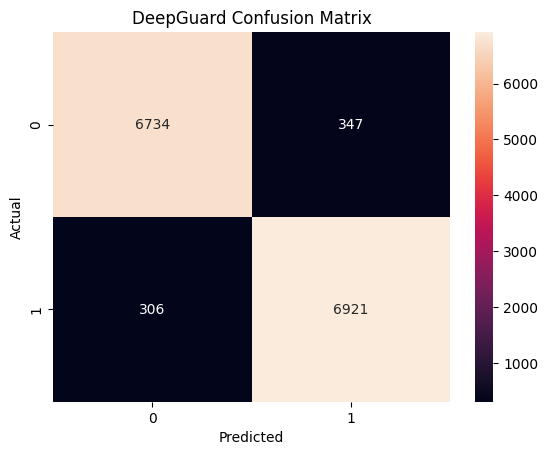

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DeepGuard Confusion Matrix")
plt.show()

In [22]:
import os

os.makedirs("../models", exist_ok=True)

In [23]:
import joblib

joblib.dump(model, "../models/text_model.pkl")
joblib.dump(vectorizer, "../models/vectorizer.pkl")

print("Model saved successfully 🚀")

Model saved successfully 🚀


In [24]:
import os

print(os.listdir("../models"))

['text_model.pkl', 'vectorizer.pkl']


In [25]:
import joblib

model = joblib.load("../models/text_model.pkl")
vectorizer = joblib.load("../models/vectorizer.pkl")

In [26]:
def predict_news(text):
    text = text.lower()
    vec = vectorizer.transform([text])
    pred = model.predict(vec)[0]
    return "FAKE" if pred == 1 else "REAL"

In [27]:
print(predict_news("Government announces new policy to improve education system"))

FAKE


In [28]:
print(predict_news("SHOCKING!!! Aliens have taken over the USA and government confirms it"))

FAKE


In [29]:
print(predict_news("Scientists discover new method to reduce pollution levels"))

FAKE


In [30]:
def predict_news(text):
    text = text.lower()
    vec = vectorizer.transform([text])
    pred = model.predict(vec)[0]

    if pred == 1:
        return "FAKE NEWS ❌"
    else:
        return "REAL NEWS ✅"

In [31]:
df["label"].value_counts()

label
1    36509
0    35028
Name: count, dtype: int64

In [32]:
df.sample(5)

,content,label
63962,podesta wiki leakswe prefer muslims over chris...,1
2886,trump commutes fraud sentence of kosher meatpa...,0
17605,facebooks ceo threatens employees to not expre...,1
32161,in illinois homecoming obama calls for improve...,0
31502,cant say under god at hilary speech cant say u...,1


In [33]:
print(df[df["label"] == 0].head())
print(df[df["label"] == 1].head())

                                              content  label
3   bobby jindal raised hindu uses story of christ...      0
11  may brexit offer would hurt cost eu citizens e...      0
12  schumer calls on trump to appoint official to ...      0
14  no change expected for espn political agenda d...      0
15  billionaire odebrecht in brazil scandal releas...      0
                                             content  label
0  law enforcement on high alert following threat...      1
2  unbelievable obamas attorney general says most...      1
4  satan russia unvelis an image of its terrifyin...      1
5  about time christian group sues amazon and spl...      1
6  dr ben carson targeted by the irs i never had ...      1


In [34]:
def predict_news(text):
    text = text.lower()
    vec = vectorizer.transform([text])

    prob = model.predict_proba(vec)[0]
    pred = model.predict(vec)[0]

    return pred, prob

In [35]:
print(predict_news("Scientists discover new method to reduce pollution levels"))

(1, array([0.19909394, 0.80090606]))


In [36]:
test_texts = [
    "Government announces new education policy",
    "Breaking news: new scientific discovery confirmed",
    "Shocking!!! Aliens landed on earth and destroyed cities",
    "Study shows climate change is accelerating"
]

for t in test_texts:
    vec = vectorizer.transform([t])
    pred = model.predict(vec)[0]
    print(pred, t)

1 Government announces new education policy
1 Breaking news: new scientific discovery confirmed
1 Shocking!!! Aliens landed on earth and destroyed cities
1 Study shows climate change is accelerating


In [1]:
 import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

In [4]:
import pandas as pd

df = pd.read_csv("../datasets/text/WELFake_Dataset.csv")

In [5]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.dropna()

df["content"] = df["title"] + " " + df["text"]

df = df[["content", "label"]]

In [6]:
print(df.shape)
df.head()

(71537, 2)


,content,label
0,LAW ENFORCEMENT ON HIGH ALERT Following Threat...,1
2,UNBELIEVABLE! OBAMA’S ATTORNEY GENERAL SAYS MO...,1
3,"Bobby Jindal, raised Hindu, uses story of Chri...",0
4,SATAN 2: Russia unvelis an image of its terrif...,1
5,About Time! Christian Group Sues Amazon and SP...,1


In [7]:
print(df[df["label"] == 0]["content"].iloc[0][:500])

Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid A dozen politically active pastors came here for a private dinner Friday night to hear a conversion story unique in the context of presidential politics: how Louisiana Gov. Bobby Jindal traveled from Hinduism to Protestant Christianity and, ultimately, became what he calls an “evangelical Catholic.”

Over two hours, Jindal, 42, recalled talking with a girl in high school who wanted to “save 


In [8]:
print(df[df["label"] == 1]["content"].iloc[0][:500])

LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11By #BlackLivesMatter And #FYF911 Terrorists [VIDEO] No comment is expected from Barack Obama Members of the #FYF911 or #FukYoFlag and #BlackLivesMatter movements called for the lynching and hanging of white people and cops. They encouraged others on a radio show Tuesday night to  turn the tide  and kill white people and cops to send a message about the killing of black people in America.One of the F***YoFlag organizer


In [11]:
import joblib

model = joblib.load("../models/text_model.pkl")
vectorizer = joblib.load("../models/vectorizer.pkl")

print("Model loaded successfully")

Model loaded successfully


In [12]:
type(model)

sklearn.linear_model._logistic.LogisticRegression

In [13]:
type(vectorizer)

sklearn.feature_extraction.text.TfidfVectorizer

In [15]:
real_sample = df[df["label"] == 0]["content"].iloc[0]
fake_sample = df[df["label"] == 1]["content"].iloc[0]

print("Prediction for REAL sample:",
      model.predict(vectorizer.transform([real_sample]))[0])

print("Prediction for FAKE sample:",
      model.predict(vectorizer.transform([fake_sample]))[0])

Prediction for REAL sample: 0
Prediction for FAKE sample: 1


In [16]:
real_sample = df[df["label"] == 0]["content"].iloc[0]

print(real_sample[:1000])

Bobby Jindal, raised Hindu, uses story of Christian conversion to woo evangelicals for potential 2016 bid A dozen politically active pastors came here for a private dinner Friday night to hear a conversion story unique in the context of presidential politics: how Louisiana Gov. Bobby Jindal traveled from Hinduism to Protestant Christianity and, ultimately, became what he calls an “evangelical Catholic.”

Over two hours, Jindal, 42, recalled talking with a girl in high school who wanted to “save my soul,” reading the Bible in a closet so his parents would not see him and feeling a stir while watching a movie during his senior year that depicted Jesus on the cross.

“I was struck, and struck hard,” Jindal told the pastors. “This was the Son of God, and He had died for our sins.”

Jindal’s session with the Christian clergy, who lead congregations in the early presidential battleground states of Iowa and South Carolina, was part of a behind-the-scenes effort by the Louisiana governor to fi

In [17]:
model.predict(vectorizer.transform([real_sample[:1000]]))

array([1], dtype=int64)

In [18]:
def predict_news(text):
    vec = vectorizer.transform([text])

    prediction = model.predict(vec)[0]
    probability = model.predict_proba(vec)[0]

    confidence = max(probability) * 100

    return prediction, confidence

In [20]:
import re

def predict_text(text):
    cleaned = re.sub(r'[^a-zA-Z\s]', '', text.lower())

    vectorized = vectorizer.transform([cleaned])

    prediction = model.predict(vectorized)
    probability = model.predict_proba(vectorized)[0]

    label = "FAKE 🔴" if prediction[0] == 1 else "REAL 🟢"
    confidence = max(probability) * 100

    return f"{label} — Confidence: {confidence:.1f}%"

In [21]:
print(predict_text(
    "LAW ENFORCEMENT ON HIGH ALERT Following Threats Against Cops And Whites On 9-11"
))

print(predict_text(
    "Bobby Jindal raised Hindu uses story of Christian conversion to woo evangelicals"
))

print(predict_text(
    "Scientists discover new method to reduce pollution levels according to recent study"
))

print(predict_text(
    "BREAKING SHARE BEFORE DELETED Government hiding shocking truth from citizens"
))

FAKE 🔴 — Confidence: 92.7%
FAKE 🔴 — Confidence: 93.2%
FAKE 🔴 — Confidence: 82.2%
FAKE 🔴 — Confidence: 99.8%


In [22]:
real_sample = df[df["label"] == 0]["content"].iloc[0]
fake_sample = df[df["label"] == 1]["content"].iloc[0]

print(predict_text(real_sample[:1000]))
print(predict_text(fake_sample[:1000]))

FAKE 🔴 — Confidence: 53.0%
FAKE 🔴 — Confidence: 88.0%


In [23]:
real_sample = df[df["label"] == 0]["content"].iloc[0]
fake_sample = df[df["label"] == 1]["content"].iloc[0]

print(predict_text(real_sample))
print(predict_text(fake_sample))

REAL 🟢 — Confidence: 91.7%
FAKE 🔴 — Confidence: 70.9%


In [24]:
long_real = """
Scientists at a leading research university have announced promising results from a new study.
The research, published in a peer-reviewed journal, suggests that the treatment may improve
patient outcomes. Further clinical trials are planned before widespread adoption.
"""

print(predict_text(long_real))

FAKE 🔴 — Confidence: 81.5%


In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report

In [3]:
df = pd.read_csv("../datasets/text/WELFake_Dataset.csv")

In [5]:
print(df.shape)

(72134, 4)


In [6]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df = df.dropna()

df["content"] = df["title"] + " " + df["text"]

df = df[["content", "label"]]

print(df.shape)

(71537, 2)


In [8]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [9]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(X_train_vec.shape)
print(X_test_vec.shape)

(57229, 5000)
(14308, 5000)


In [10]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_vec, y_train)

log_pred = log_model.predict(X_test_vec)

print("Logistic Regression Accuracy:", accuracy_score(y_test, log_pred))
print(classification_report(y_test, log_pred))

Logistic Regression Accuracy: 0.947441990494828
              precision    recall  f1-score   support

           0       0.95      0.94      0.95      7081
           1       0.94      0.95      0.95      7227

    accuracy                           0.95     14308
   macro avg       0.95      0.95      0.95     14308
weighted avg       0.95      0.95      0.95     14308



In [12]:
nb_model = MultinomialNB()

nb_model.fit(X_train_vec, y_train)

nb_pred = nb_model.predict(X_test_vec)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))
print(classification_report(y_test, nb_pred))

Naive Bayes Accuracy: 0.8486860497623707
              precision    recall  f1-score   support

           0       0.87      0.82      0.84      7081
           1       0.83      0.87      0.85      7227

    accuracy                           0.85     14308
   macro avg       0.85      0.85      0.85     14308
weighted avg       0.85      0.85      0.85     14308



In [3]:
from sklearn.svm import SVC

In [5]:
svm_model = SVC(kernel='linear', probability=True)

In [7]:
%whos

Variable    Type       Data/Info
--------------------------------
SVC         ABCMeta    <class 'sklearn.svm._classes.SVC'>
svm_model   SVC        SVC(kernel='linear', probability=True)


In [8]:
svm_model = SVC(kernel='linear', probability=True)

svm_model.fit(X_train_vec, y_train)

svm_pred = svm_model.predict(X_test_vec)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))

NameError: name 'X_train_vec' is not defined

In [ ]:
print("=== FINAL MODEL COMPARISON ===")
print("Logistic Regression:", accuracy_score(y_test, log_pred))
print("Naive Bayes:", accuracy_score(y_test, nb_pred))
print("SVM:", accuracy_score(y_test, svm_pred))

In [ ]:
import joblib

joblib.dump(log_model, "../models/text_model.pkl")

In [ ]:
joblib.dump(vectorizer, "../models/vectorizer.pkl")

In [ ]:
import os

print(os.listdir("../models"))

In [9]:
%whos

Variable    Type       Data/Info
--------------------------------
SVC         ABCMeta    <class 'sklearn.svm._classes.SVC'>
svm_model   SVC        SVC(kernel='linear', probability=True)


In [10]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

In [11]:
df = pd.read_csv("../datasets/text/WELFake_Dataset.csv")

df = df.drop(columns=["Unnamed: 0"], errors="ignore")
df = df.dropna()

df["content"] = df["title"] + " " + df["text"]

df = df[["content", "label"]]

In [12]:
X = df["content"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [13]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train_vec = vectorizer.fit_transform(X_train)
X_test_vec = vectorizer.transform(X_test)

print(X_train_vec.shape)
print(X_test_vec.shape)

(57229, 5000)
(14308, 5000)


In [ ]:
for i in range(10):
    text = X_test.iloc[i]
    actual = y_test.iloc[i]
    predicted = log_model.predict(vectorizer.transform([text]))[0]

    print(f"Actual: {actual} | Predicted: {predicted}")

In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, log_pred)

print(cm)